---
title: "Issued 1 November 2023: the next six seasons"
subtitle: "Three-month rainfall forecasts for Indonesia from one CFSv2 start, December-February to May-July, calibrated with CCA and PCR"
description: "Download CFSv2 started on 1 November 2023, build CHIRPS v3.0 three-month totals from dekads for each of the next six overlapping seasons, fit CCA and PCR at each lead with PyCPT, score the hindcasts and the forecasts as issued, and compare with the monthly case and with forecasting one season from earlier starts."
execute:
  enabled: false
---

A forecast centre issues an outlook on one date and looks several seasons ahead.
This notebook does exactly that: it takes the CFSv2 run started on **1 November
2023** and makes a calibrated forecast for each of the next six seasons, from
December-February to May-July. Lead 1 is the season starting one month after the issue
date, lead 6 the one starting six months after it.

Because each lead is a different calendar season, a change in skill from one
lead to the next mixes two things: forecasting further ahead, and some seasons
being easier to forecast than others. Section 6 separates them by doing the
opposite as well: one target, October-December 2023, forecast from six earlier starts.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine, internet access the first time
(CFSv2 files from the IRI Data Library, no key needed), and the CHIRPS v3.0
dekadal archive described in step 2. Eighteen fits take several minutes; times are
printed below.
:::

## 1. One issue date, six targets

The **lead** is the number of whole months between the issue date and the first
day of the target. PyCPT counts each target month from the start to its middle,
so its own leads are half a month larger (seasons of three months span three
PyCPT leads). Training uses the **target** years 1991-2020, as PyCPT's
`target_first_year` and `target_final_year` define them: for a target in
January or later, the 1 November starts are those of the year before. The cell asks
PyCPT for both.

In [1]:
from pathlib import Path
import datetime as dt
import json
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader
import cptdl as dl
import pycpt
from pycpt import notebook as pycpt_notebook

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
from pycpt_tutorial.country_grid import aggregate_country_rainfall, training_complete_mask
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import checks, figures
figures.use_style()

predictor_names = ["CFSv2.PRCP"]
predictand_name = "CHIRPS3.PRCP"
issue = dt.datetime(2023, 11, 1)
leads = [1, 2, 3, 4, 5, 6]                       # months from the issue date to the first day of the target
target_length = 3                          # months in each target
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
targets = {lead: f"{MONTHS[(issue.month - 1 + lead) % 12]}-{MONTHS[(issue.month - 2 + lead + target_length) % 12]}"
           for lead in leads}
predictor_extent = {"west": 85, "east": 155, "south": -20, "north": 20}
predictand_extent = {"west": 94, "east": 142, "south": -12, "north": 7}
training_years = list(range(1991, 2021))          # target years
cpt_args = {
    "transform_predictand": None,
    "tailoring": None,
    "cca_modes": (2, 2),
    "x_eof_modes": (3, 3),
    "y_eof_modes": (3, 3),
    "validation": "crossvalidation",
    "drymask_threshold": None,
    "skillmask_threshold": None,
    "crossvalidation_window": 5,
    "synchronous_predictors": True,
}
force_download = False
case_root = Path.home() / "PyCPT" / "indonesia-issued-2023-11-seasons"

# Section 7: one target forecast from six earlier starts (the design of the earlier version of this case)
fixed_target = "Oct-Dec"
fixed_starts = {lead: dt.datetime(2023, 10 - lead, 1) for lead in leads}
fixed_root = Path.home() / "PyCPT" / "indonesia-ond-2023-leads"

rows = []
for lead, target in targets.items():
    low, high = dl.leads_from_target(issue, target)
    delta = pycpt_notebook.issue_year_delta(issue.month, target)
    rows.append({"lead (months)": lead, "target": target, "PyCPT lead": f"{low} to {high}",
                 "hindcast starts": f"1 Nov {training_years[0] + delta}-{training_years[-1] + delta}",
                 "2023 start": issue.strftime("%d %b %Y")})
pd.DataFrame(rows).set_index("lead (months)")

,target,PyCPT lead,hindcast starts,2023 start
lead (months),,,,
1,Dec-Feb,1.5 to 3.5,1 Nov 1990-2019,01 Nov 2023
2,Jan-Mar,2.5 to 4.5,1 Nov 1990-2019,01 Nov 2023
3,Feb-Apr,3.5 to 5.5,1 Nov 1990-2019,01 Nov 2023
4,Mar-May,4.5 to 6.5,1 Nov 1990-2019,01 Nov 2023
5,Apr-Jun,5.5 to 7.5,1 Nov 1990-2019,01 Nov 2023
6,May-Jul,6.5 to 8.5,1 Nov 1990-2019,01 Nov 2023


## 2. Observations from dekads

The predictand is CHIRPS v3.0 rainfall from the local **dekadal** archive (three
accumulation periods per month: days 1-10, 11-20 and 21 to the end), the same
archive family as [chapter 3](../learn/03-local-observations.ipynb). Its metadata
says exact zeros are kept. A target total is the sum of the dekads that tile it.
The function below finds them from the stored time bounds and refuses to sum
unless they run contiguously from the target's first day to the day after its last.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
print("Variable attributes:", {k: source.precip.attrs[k] for k in ("units", "cell_methods", "comment")})
bounds = pd.DatetimeIndex(source.time_bnds.values.ravel()).values.reshape(-1, 2)
dekad_first, dekad_end = pd.DatetimeIndex(bounds[:, 0]), pd.DatetimeIndex(bounds[:, 1])
print(f"Dekads in the archive: {len(dekad_first)}, {dekad_first[0]:%d %b %Y} to {dekad_end[-1]:%d %b %Y}")
box = predictand_extent
region = source.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))


def period_total(first, last):
    # Sum of the dekads covering first..last (inclusive days), checked against the stored bounds.
    end = pd.Timestamp(last) + pd.Timedelta(days=1)
    index = np.flatnonzero((dekad_first >= pd.Timestamp(first)) & (dekad_end <= end))
    assert len(index) > 0 and dekad_first[index[0]] == pd.Timestamp(first) and dekad_end[index[-1]] == end, (first, last)
    assert (dekad_first[index[1:]] == dekad_end[index[:-1]]).all(), (first, last)
    return region.isel(time=index).sum("time", skipna=False)

Variable attributes: {'units': 'mm', 'cell_methods': 'time: sum', 'comment': 'Exact zeros are preserved, for a zero-inflated distribution fit. NaN marks no data.'}
Dekads in the archive: 1620, 01 Jan 1981 to 01 Jan 2026


A consistency check against a separately stored product: the archive also has
3-month totals (the file chapter 3 used). December-February built from nine dekads
should equal the stored total. The cell compares them for the first training season
and for the 2023-24 season.

In [3]:
rolling = xr.open_dataset("/mnt/e/temp/chirps/rolling_dekad/wld_cli_chirps3_month3_bydekad_1981_2025.nc")
rolling_first = pd.DatetimeIndex(rolling.time_bnds.values[:, 0])
rolling_end = pd.DatetimeIndex(rolling.time_bnds.values[:, 1])
for year in [1990, 2023]:
    first, last = pd.Timestamp(year, 12, 1), pd.Timestamp(year + 1, 2, 1) + pd.offsets.MonthEnd(0)
    k = int(np.flatnonzero((rolling_first == first) & (rolling_end == last + pd.Timedelta(days=1)))[0])
    stored = rolling.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"])).isel(time=k).load()
    from_dekads = period_total(first, last).load()
    gap = abs(from_dekads - stored)
    print(f"DJF {year}-{(year + 1) % 100:02d} ({first:%d %b %Y} to {last:%d %b %Y}): largest difference {float(gap.max()):.4f} mm, "
          f"same missing pixels: {bool((from_dekads.isnull() == stored.isnull()).all())}")

DJF 1990-91 (01 Dec 1990 to 28 Feb 1991): largest difference 0.0002 mm, same missing pixels: True


DJF 2023-24 (01 Dec 2023 to 29 Feb 2024): largest difference 0.0005 mm, same missing pixels: True


The predictand keeps CHIRPS v3.0's **native 0.05° grid**: every pixel whose centre
lies inside Indonesia (Natural Earth 1:10m), with no averaging to coarser cells. A
pixel enters the fits only if it has data in all 30 training years **of every target
used on this page** (the six leads and the OND target of section 6), so
every area mean covers the same pixels. Area means weight each pixel by the cosine
of its latitude.

In [4]:
records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(region.lon, region.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"),
                       coords={"lat": region.lat, "lon": region.lon})
print(f"Native pixels inside Indonesia: {int(country.sum()):,}")


def observed_cells(data):
    # Target totals at the native 0.05 degree pixels inside Indonesia, on the T, Ti, Tf axis of a PyCPT file.
    native = xr.concat([period_total(a, b) for a, b in zip(data["Ti"].values, data["Tf"].values)],
                       dim=pd.Index(data["T"].values, name="T")).load()
    zeros = int(((native == 0) & country).sum())
    pixels = native.where(country).rename({"lat": "Y", "lon": "X"})
    pixels = pixels.assign_coords(Y=np.round(pixels["Y"].values.astype(float), 3), X=np.round(pixels["X"].values.astype(float), 3))
    pixels = pixels.sortby("Y", ascending=False).astype("float32")
    return pixels.assign_coords(Ti=("T", data["Ti"].values), Tf=("T", data["Tf"].values)), zeros

Native pixels inside Indonesia: 61,192


## 3. One case folder per lead

Each lead is its own forecast question, so each gets its own case folder
([chapter 7](../learn/07-adapt-your-region.ipynb) explains why folders should not
be shared between questions). The hindcasts are downloaded first, because their
`T`, `Ti` and `Tf` say exactly which days each training target covers; the
observations are then built for those days and saved as that folder's local
predictand file. The OND starts of section 6 are prepared the same way.

In [5]:
def prepare(name, args, folder):
    domain_dir = pycpt.setup(folder, predictor_extent)
    hindcasts = pycpt_notebook.download_hindcasts(predictor_names, domain_dir, force_download, args)[0]
    assert (pd.DatetimeIndex(hindcasts["T"].values).year == np.array(training_years)).all()
    Yl, zeros = observed_cells(hindcasts)
    return dict(name=name, args=args, domain_dir=domain_dir, folder=folder, Y_all=Yl, zeros=zeros,
                complete=training_complete_mask(Yl, training_years))


start = time.monotonic()
questions = {}
for lead, target in targets.items():
    args = dict(fdate=issue, target=target, target_first_year=training_years[0], target_final_year=training_years[-1],
                predictor_extent=predictor_extent, predictand_extent=predictand_extent)
    questions["issue", lead] = prepare(target, args, case_root / f"lead-{lead}")
for lead, fdate in fixed_starts.items():
    args = dict(fdate=fdate, target=fixed_target, target_first_year=training_years[0], target_final_year=training_years[-1],
                predictor_extent=predictor_extent, predictand_extent=predictand_extent)
    questions["fixed", lead] = prepare(fixed_target, args, fixed_root / f"lead-{lead}")
cells = xr.concat([q["complete"] for q in questions.values()], "q").all("q")
print(f"Hindcast axes and observations for {len(questions)} questions in {time.monotonic() - start:.0f} s")
print(f"Pixels with data in all 30 training years of every target: {int(cells.sum()):,} "
      f"(per target: {sorted({int(q['complete'].sum()) for q in questions.values()})})")
print("Indonesian native pixel-targets at exactly 0 mm, by lead:",
      {lead: questions["issue", lead]["zeros"] for lead in leads})

Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-1/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-1/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-1/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-2/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-2/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-2/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-3/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-3/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-3/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-4/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-4/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-4/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-5/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-5/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-5/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-6/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-6/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-seasons/lead-6/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



... (3 outputs left out)

Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-4/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-4/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-4/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-5/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-5/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-5/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-6/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-6/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-leads/lead-6/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Hindcast axes and observations for 12 questions in 118 s
Pixels with data in all 30 training years of every target: 61,190 (per target: [61190])
Indonesian native pixel-targets at exactly 0 mm, by lead: {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 1}


In [6]:
inputs, rows, warnings = {}, [], set()
for key, q in questions.items():
    Yl = q["Y_all"].where(cells).transpose("T", "Y", "X").rename("precipitation")
    Yl.attrs = {"units": "mm", "missing": -999.0,
                "long_name": f"CHIRPS v3.0 {q['name']} rainfall total, Indonesia land, native 0.05 degree"}
    local_file = q["folder"] / f"local-CHIRPS3-{q['name']}-1991-2020.nc"
    save_netcdf(Yl.to_dataset(), local_file, overwrite=True,
                metadata={"source_file": chirps3_file.name,
                          "aggregation": "sum of the dekads tiling each target; native 0.05 degree pixels whose centre lies inside Indonesia",
                          "boundary": "Natural Earth 1:10m admin_0_countries, ADM0_A3=IDN",
                          "training_years": "target years 1991-2020"})
    checks.remember_question(q["args"], q["domain_dir"])
    Yd, X, F = pycpt.download_data(predictand_name, local_file, predictor_names, q["args"], q["domain_dir"], force_download)
    same_axis = bool((X[0]["T"].values == Yl["T"].values).all() and (X[0]["Ti"].values == Yl["Ti"].values).all()
                     and (X[0]["Tf"].values == Yl["Tf"].values).all())
    table = checks.check_case(q["args"], predictand_name, Yd, X, F, predictor_names, q["domain_dir"])
    warnings |= {f"{r.check}: {r.detail}" for r in table.itertuples() if r.status == "warn"}
    inputs[key] = dict(q, Y=Yd, Yl=Yl, X=X, F=F)
    s0, f0 = pd.Timestamp(X[0]["S"].values[0]), pd.Timestamp(F[0]["S"].values[0])
    rows.append({"design": key[0], "lead": key[1], "target": q["name"],
                 "hindcast starts": f"{s0:%d %b} {s0.year}-{pd.Timestamp(X[0]['S'].values[-1]).year}",
                 "training targets": f"{pd.Timestamp(Yl['Ti'].values[0]):%d %b %Y} ... {pd.Timestamp(Yl['Tf'].values[-1]):%d %b %Y}",
                 "forecast start": f"{f0:%d %b %Y}",
                 "forecast target": f"{pd.Timestamp(F[0]['Ti'].values[0]):%d %b %Y} to {pd.Timestamp(F[0]['Tf'].values[0]):%d %b %Y}",
                 "same T, Ti, Tf as Y": same_axis, "preflight": checks.summary(table)})
print("Preflight warnings (all questions):", *sorted(warnings), sep="\n  ")
pd.DataFrame(rows).set_index(["design", "lead"])

Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



... (3 outputs left out)

Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

Preflight warnings (all questions):
  CFSv2.PRCP: units label: units attribute is 'mm/day', a rate; the catalog requests examined in chapter 1 multiply by the season length, so confirm whether the values are rates or seasonal totals.


target   hindcast starts             training targets  \
design lead                                                           
issue  1     Dec-Feb  01 Nov 1990-2019  01 Dec 1990 ... 29 Feb 2020   
       2     Jan-Mar  01 Nov 1990-2019  01 Jan 1991 ... 31 Mar 2020   
       3     Feb-Apr  01 Nov 1990-2019  01 Feb 1991 ... 30 Apr 2020   
       4     Mar-May  01 Nov 1990-2019  01 Mar 1991 ... 31 May 2020   
       5     Apr-Jun  01 Nov 1990-2019  01 Apr 1991 ... 30 Jun 2020   
       6     May-Jul  01 Nov 1990-2019  01 May 1991 ... 31 Jul 2020   
fixed  1     Oct-Dec  01 Sep 1991-2020  01 Oct 1991 ... 31 Dec 2020   
       2     Oct-Dec  01 Aug 1991-2020  01 Oct 1991 ... 31 Dec 2020   
       3     Oct-Dec  01 Jul 1991-2020  01 Oct 1991 ... 31 Dec 2020   
       4     Oct-Dec  01 Jun 1991-2020  01 Oct 1991 ... 31 Dec 2020   
       5     Oct-Dec  01 May 1991-2020  01 Oct 1991 ... 31 Dec 2020   
       6     Oct-Dec  01 Apr 1991-2020  01 Oct 1991 ... 31 Dec 2020   

            forecast start             forecast target  same T, Ti, Tf as Y  \
design lead                                                                   
issue  1       01 Nov 2023  01 Dec 2023 to 29 Feb 2024                 True   
       2       01 Nov 2023  01 Jan 2024 to 31 Mar 2024                 True   
       3       01 Nov 2023  01 Feb 2024 to 30 Apr 2024                 True   
       4       01 Nov 2023  01 Mar 2024 to 31 May 2024                 True   
       5       01 Nov 2023  01 Apr 2024 to 30 Jun 2024                 True   
       6       01 Nov 2023  01 May 2024 to 31 Jul 2024                 True   
fixed  1       01 Sep 2023  01 Oct 2023 to 31 Dec 2023                 True   
       2       01 Aug 2023  01 Oct 2023 to 31 Dec 2023                 True   
       3       01 Jul 2023  01 Oct 2023 to 31 Dec 2023                 True   
       4       01 Jun 2023  01 Oct 2023 to 31 Dec 2023                 True   
       5       01 May 2023  01 Oct 2023 to 31 Dec 2023                 True   
       6       01 Apr 2023  01 Oct 2023 to 31 Dec 2023                 True   

                                    preflight  
design lead                                    
issue  1     {'ok': 10, 'warn': 1, 'fail': 0}  
       2     {'ok': 10, 'warn': 1, 'fail': 0}  
       3     {'ok': 10, 'warn': 1, 'fail': 0}  
       4     {'ok': 10, 'warn': 1, 'fail': 0}  
       5     {'ok': 10, 'warn': 1, 'fail': 0}  
       6     {'ok': 10, 'warn': 1, 'fail': 0}  
fixed  1     {'ok': 10, 'warn': 1, 'fail': 0}  
       2     {'ok': 10, 'warn': 1, 'fail': 0}  
       3     {'ok': 10, 'warn': 1, 'fail': 0}  
       4     {'ok': 10, 'warn': 1, 'fail': 0}  
       5     {'ok': 10, 'warn': 1, 'fail': 0}  
       6     {'ok': 10, 'warn': 1, 'fail': 0}

Units: the downloaded files say `mm/day`, but each request multiplies the daily
mean by the number of days in the target (the `/mul` step in PyCPT's request), so
the values are totals in millimetres, as
[chapter 2](../learn/02-getting-data.ipynb) found. PyCPT's month lengths give
February 28.25 days in every year (`monthlengths` in `cptdl/targetleadconv.py`),
while the observations have 28 or 29. Regression onto the observed totals absorbs a
constant factor, and correlation ignores it. The cell reads the factor from each
request and compares the hindcasts' 1991-2020 mean with the observed mean.

In [7]:
weights = np.cos(np.deg2rad(cells["Y"])) * cells
rows = []
for lead in leads:
    d = inputs["issue", lead]
    url = dl.evaluate_url(dl.hindcasts[predictor_names[0]], **pycpt_notebook._preprocess_download_args(d["args"]))
    X = d["X"][0]
    X = X.where((X > -999) & (X["X"] >= box["west"]) & (X["X"] <= box["east"]) & (X["Y"] >= box["south"]) & (X["Y"] <= box["north"]))
    rows.append({"lead": lead, "target": d["name"], "units attribute": d["X"][0].attrs.get("units"),
                 "multiplied by (days)": float(re.search(r"/([\d.]+)/mul", url).group(1)),
                 "CFSv2 1991-2020 mean over the box (mm)": round(float(X.mean("T").weighted(np.cos(np.deg2rad(X["Y"]))).mean()), 1),
                 "observed 1991-2020 mean, Indonesian pixels (mm)": round(float(d["Yl"].mean("T").weighted(weights).mean()), 1)})
pd.DataFrame(rows).set_index("lead")

,target,units attribute,multiplied by (days),CFSv2 1991-2020 mean over the box (mm),"observed 1991-2020 mean, Indonesian pixels (mm)"
lead,,,,,
1,Dec-Feb,mm/day,90.25,727.3,842.0
2,Jan-Mar,mm/day,90.25,700.2,830.8
3,Feb-Apr,mm/day,89.25,644.4,830.9
4,Mar-May,mm/day,92.00,633.3,816.4
5,Apr-Jun,mm/day,91.00,601.8,733.5
6,May-Jul,mm/day,92.00,556.0,631.9


## 4. Twelve fits, and six more

CCA and PCR at each lead, with the settings fixed above, through PyCPT's own
`evaluate_models`; then CCA for the six starts of section 6. At 0.05° one fit takes
several minutes, most of it spent writing and reading CPT's files for 61,000 pixels,
so the eighteen fits run side by side, each `evaluate_models` call in its own Python
process with its own CPT workspace. As
[chapter 4](../learn/04-evaluate-models.ipynb) showed, the deterministic skill
scores describe cross-validated hindcasts (window of 5), while the probabilistic
ones are in-sample. Only the deterministic ones are used for skill below.

In [8]:
import multiprocessing
from concurrent.futures import ProcessPoolExecutor


def fit(job):
    # One PyCPT fit, in its own process (forked, so it shares the inputs above); CPT works in its own workspace.
    key, MOS = job
    d = inputs[key]
    start = time.monotonic()
    hcsts, fcsts, skill, pxs, pys = pycpt.evaluate_models(d["X"], MOS, d["Y"], d["F"], cpt_args, d["domain_dir"], predictor_names)
    return key + (MOS,), dict(fcsts=fcsts[0], skill=skill[0], seconds=time.monotonic() - start)


jobs = [(key, MOS) for key in inputs for MOS in (["CCA", "PCR"] if key[0] == "issue" else ["CCA"])]
start = time.monotonic()
with ProcessPoolExecutor(max_workers=len(jobs), mp_context=multiprocessing.get_context("fork")) as pool:
    results = dict(pool.map(fit, jobs))
print(f"{len(jobs)} fits in {(time.monotonic() - start) / 60:.0f} min wall time; minutes per fit:",
      {f"{k[0]}-{k[1]}-{k[2]}": round(r["seconds"] / 60, 1) for k, r in results.items()})

18 fits in 17 min wall time; minutes per fit: {'issue-1-CCA': 17.3, 'issue-1-PCR': 15.7, 'issue-2-CCA': 16.9, 'issue-2-PCR': 16.3, 'issue-3-CCA': 16.1, 'issue-3-PCR': 15.2, 'issue-4-CCA': 16.1, 'issue-4-PCR': 15.5, 'issue-5-CCA': 16.2, 'issue-5-PCR': 17.2, 'issue-6-CCA': 16.2, 'issue-6-PCR': 16.3, 'fixed-1-CCA': 16.3, 'fixed-2-CCA': 16.1, 'fixed-3-CCA': 17.2, 'fixed-4-CCA': 16.9, 'fixed-5-CCA': 16.2, 'fixed-6-CCA': 17.3}


## 5. Skill by lead

Each score is first computed at every pixel, then summarised over Indonesia as an
area-weighted mean (weights: cosine of latitude). Three deterministic scores:

- **Pearson correlation** of the cross-validated hindcasts with the observations,
  1991-2020. Zero means no linear relationship.
- **2AFC**, the chance (in %) that the hindcasts rank two different years in the
  observed order. 50% is what a forecast without skill would get.
- **ROC area** for below- and above-normal seasons. 0.5 is no skill.

The **raw CFSv2** row is a baseline without calibration: the model's own
hindcasts, interpolated linearly from 1° to the pixel centres, correlated with the
same observations. Correlation ignores the model's bias, so this is a fair
comparison for that one score.

Remember that each lead is also a different season: lead 1 is December
-February, lead 6 is May-July.

In [9]:
grid_Y, grid_X = cells["Y"], cells["X"]


def on_grid(a):
    return a.where(a > -999).reindex(Y=grid_Y, X=grid_X, method="nearest", tolerance=1e-3)


def area_mean(field):
    return float(on_grid(field).where(cells).weighted(weights).mean(("Y", "X")))


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


def raw_correlation(d):
    X = d["X"][0].where(d["X"][0] > -999).interp(Y=grid_Y, X=grid_X, method="linear")
    return pearson(X.reset_coords(drop=True), d["Yl"].reset_coords(drop=True)).where(cells)


label = {}
for lead in leads:
    F = inputs["issue", lead]["F"][0]
    a, b = pd.Timestamp(F["Ti"].values[0]), pd.Timestamp(F["Tf"].values[0])
    label[lead] = f"{a:%b %Y}" if target_length == 1 else (
        "".join(MONTHS[(a.month - 1 + k) % 12][0] for k in range(3)) + (f" {a.year}-{b.year % 100:02d}" if a.year != b.year else f" {a.year}"))
raw_pearson = {lead: raw_correlation(inputs["issue", lead]) for lead in leads}

rows = []
for lead in leads:
    for MOS in ["CCA", "PCR"]:
        s = results["issue", lead, MOS]["skill"]
        rows.append({"lead": lead, "target": label[lead], "method": MOS,
                     "Pearson": area_mean(s.pearson), "2AFC (%)": area_mean(s.two_alternative_forced_choice),
                     "ROC below normal": area_mean(s.roc_area_below_normal), "ROC above normal": area_mean(s.roc_area_above_normal),
                     "RMSE (mm)": area_mean(s.root_mean_squared_error)})
    rows.append({"lead": lead, "target": label[lead], "method": "raw CFSv2", "Pearson": area_mean(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

target  Pearson  2AFC (%)  ROC below normal  \
lead method                                                        
1    CCA        DJF 2023-24    0.163    55.568             0.571   
     PCR        DJF 2023-24    0.177    56.633             0.589   
     raw CFSv2  DJF 2023-24    0.131       NaN               NaN   
2    CCA           JFM 2024    0.031    51.619             0.508   
     PCR           JFM 2024    0.048    51.598             0.503   
     raw CFSv2     JFM 2024    0.157       NaN               NaN   
3    CCA           FMA 2024    0.039    52.010             0.522   
     PCR           FMA 2024    0.053    52.486             0.528   
     raw CFSv2     FMA 2024    0.187       NaN               NaN   
4    CCA           MAM 2024    0.008    50.919             0.501   
     PCR           MAM 2024    0.006    50.840             0.503   
     raw CFSv2     MAM 2024    0.186       NaN               NaN   
5    CCA           AMJ 2024   -0.101    47.366             0.450   
     PCR           AMJ 2024   -0.046    48.124             0.459   
     raw CFSv2     AMJ 2024    0.123       NaN               NaN   
6    CCA           MJJ 2024   -0.011    49.659             0.467   
     PCR           MJJ 2024    0.038    51.296             0.494   
     raw CFSv2     MJJ 2024    0.230       NaN               NaN   

                ROC above normal  RMSE (mm)  
lead method                                  
1    CCA                   0.562    164.907  
     PCR                   0.581    165.546  
     raw CFSv2               NaN        NaN  
2    CCA                   0.526    183.364  
     PCR                   0.532    186.378  
     raw CFSv2               NaN        NaN  
3    CCA                   0.521    171.670  
     PCR                   0.535    177.963  
     raw CFSv2               NaN        NaN  
4    CCA                   0.527    183.053  
     PCR                   0.520    188.955  
     raw CFSv2               NaN        NaN  
5    CCA                   0.473    187.160  
     PCR                   0.477    192.995  
     raw CFSv2               NaN        NaN  
6    CCA                   0.521    199.904  
     PCR                   0.537    200.279  
     raw CFSv2               NaN        NaN

The same numbers as a chart: one row per lead, the area-weighted mean as a dot,
and the middle half of the pixels (25th to 75th percentile) as a bar, so the
spread across Indonesia is visible alongside the average.

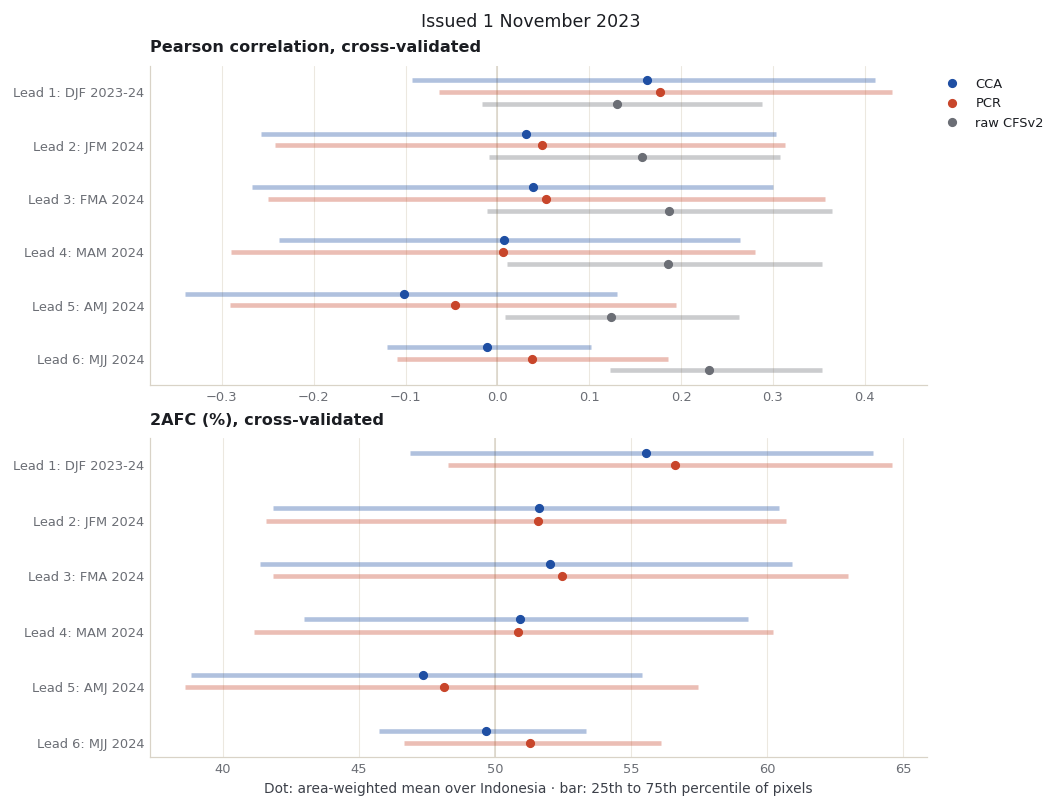

In [10]:
def quartiles(field):
    return np.nanpercentile(on_grid(field).where(cells).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw CFSv2": figures.MUTED}
panels = [("Pearson", "pearson", "Pearson correlation, cross-validated", 0),
          ("2AFC (%)", "two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 7.2), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw CFSv2" and metric != "pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw CFSv2" else results["issue", lead, method]["skill"][metric]
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [f"Lead {lead}: {label[lead]}" for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of pixels")
fig.suptitle("Issued 1 November 2023")
assets = repo / "docs/assets/seasonal-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

Where the skill sits matters as much as how much there is. The maps show the
cross-validated CCA correlation at each lead, in one column from lead 1 (top) to
lead 6 (bottom).

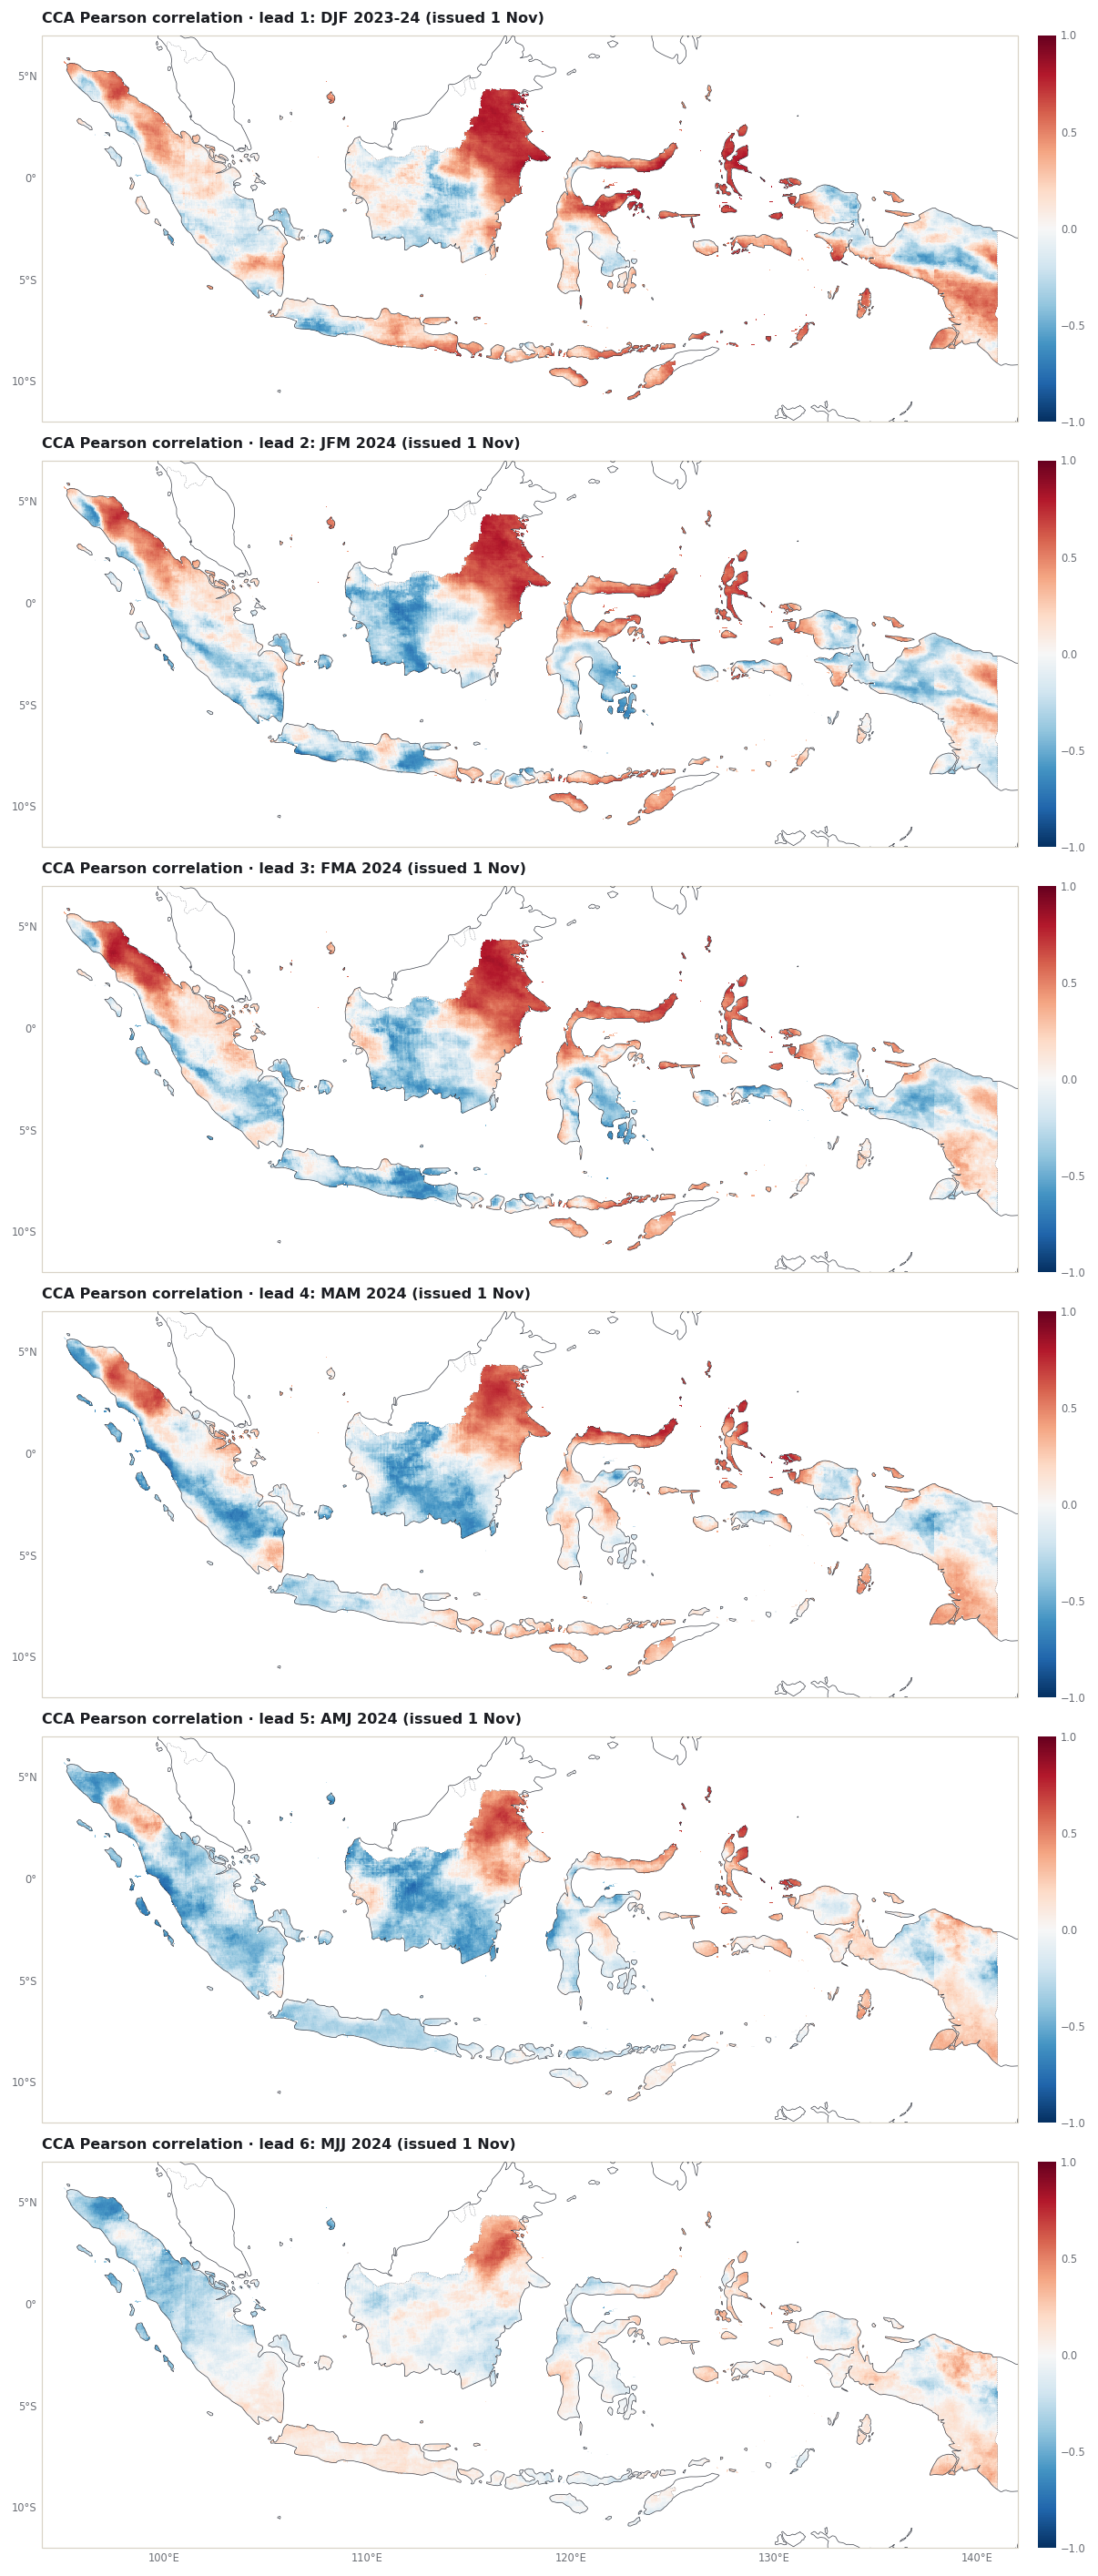

In [11]:
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    field = results["issue", lead, "CCA"]["skill"].pearson
    image = figures.draw_field(ax, field.where(field > -999), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · lead {lead}: {label[lead]} (issued 1 Nov)")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 6. Is it the lead or the season?

The same CCA settings, now for one target, **October-December 2023**, forecast from
starts one to six months before it (1 September back to 1 April). Here
the target is fixed and only the lead changes. Side by side with section 5, at
each lead: if the two lines fall together, skill is mostly lost with lead time;
if they part, the target season matters as much as how far ahead it is.

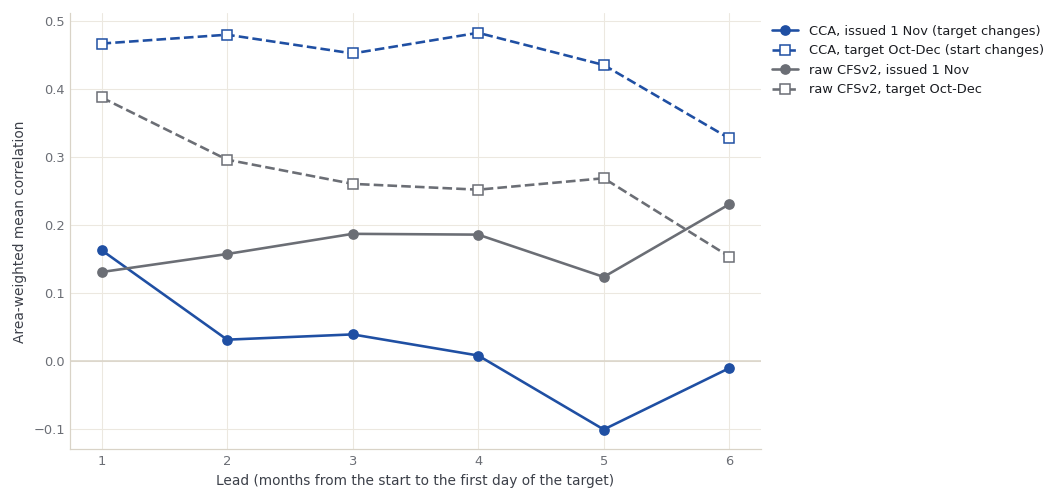

,start,target,CCA Pearson,raw CFSv2 Pearson,CCA 2AFC (%),"CCA Pearson, issued 1 Nov","raw CFSv2 Pearson, issued 1 Nov"
lead,,,,,,,
1,2023-09-01,Oct-Dec,0.467,0.388,66.583,0.163,0.131
2,2023-08-01,Oct-Dec,0.480,0.296,66.883,0.031,0.157
3,2023-07-01,Oct-Dec,0.452,0.260,66.372,0.039,0.187
4,2023-06-01,Oct-Dec,0.483,0.252,67.008,0.008,0.186
5,2023-05-01,Oct-Dec,0.435,0.269,65.859,-0.101,0.123
6,2023-04-01,Oct-Dec,0.327,0.153,61.803,-0.011,0.230


In [12]:
rows = []
for lead in leads:
    d = inputs["fixed", lead]
    rows.append({"lead": lead, "start": fixed_starts[lead].date().isoformat(), "target": d["name"],
                 "CCA Pearson": area_mean(results["fixed", lead, "CCA"]["skill"].pearson),
                 "raw CFSv2 Pearson": area_mean(raw_correlation(d)),
                 "CCA 2AFC (%)": area_mean(results["fixed", lead, "CCA"]["skill"].two_alternative_forced_choice)})
same_target = pd.DataFrame(rows).set_index("lead")
same_target["CCA Pearson, issued 1 Nov"] = [skill_by_lead.loc[(lead, "CCA"), "Pearson"] for lead in leads]
same_target["raw CFSv2 Pearson, issued 1 Nov"] = [skill_by_lead.loc[(lead, "raw CFSv2"), "Pearson"] for lead in leads]

fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 4.4), layout="constrained")
ax.axhline(0, color=figures.LINE, linewidth=1)
for column, colour, style, name in [("CCA Pearson, issued 1 Nov", figures.ACCENT, "-o", "CCA, issued 1 Nov (target changes)"),
                                    ("CCA Pearson", figures.ACCENT, "--s", f"CCA, target {fixed_target} (start changes)"),
                                    ("raw CFSv2 Pearson, issued 1 Nov", figures.MUTED, "-o", "raw CFSv2, issued 1 Nov"),
                                    ("raw CFSv2 Pearson", figures.MUTED, "--s", f"raw CFSv2, target {fixed_target}")]:
    ax.plot(leads, same_target[column], style, color=colour, label=name, markerfacecolor="white" if "--" in style else colour)
ax.set_xticks(leads, [f"{lead}" for lead in leads])
ax.set_xlabel("Lead (months from the start to the first day of the target)")
ax.set_ylabel("Area-weighted mean correlation")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "same-target-vs-issue.png")
plt.show()
same_target.round(3)

## 7. Seasons and months from the same start

The [monthly case](monthly-leads-2023.ipynb) used the same start (1 November 2023),
model, observations, grid, settings and lead definition for single months, so the
two can be set side by side: at each lead, the season and its first month. Its
scores are read from the file that notebook saved.

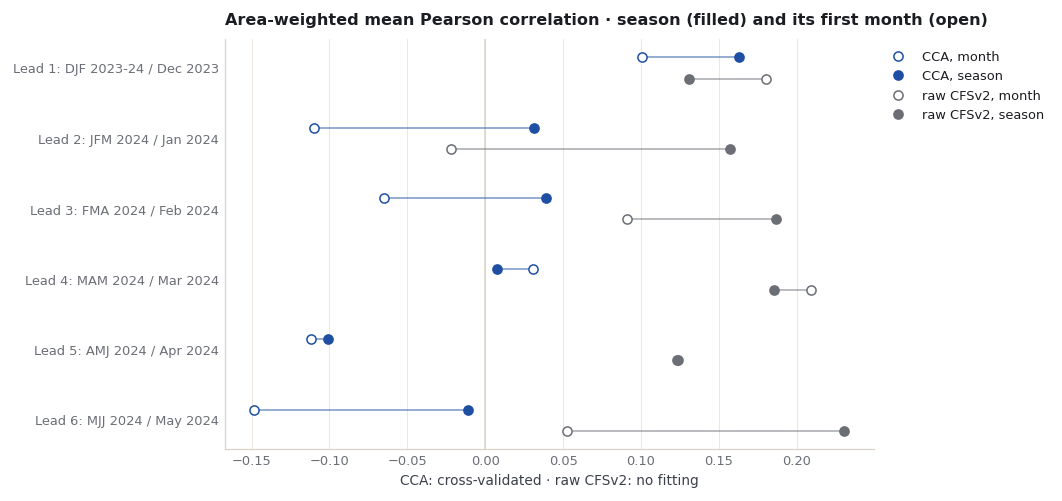

season     month  Pearson, season  Pearson, month  \
lead method                                                              
1    CCA        DJF 2023-24  Dec 2023            0.163           0.101   
     PCR        DJF 2023-24  Dec 2023            0.177           0.094   
     raw CFSv2  DJF 2023-24  Dec 2023            0.131           0.180   
2    CCA           JFM 2024  Jan 2024            0.031          -0.110   
     PCR           JFM 2024  Jan 2024            0.048          -0.092   
     raw CFSv2     JFM 2024  Jan 2024            0.157          -0.022   
3    CCA           FMA 2024  Feb 2024            0.039          -0.065   
     PCR           FMA 2024  Feb 2024            0.053          -0.054   
     raw CFSv2     FMA 2024  Feb 2024            0.187           0.091   
4    CCA           MAM 2024  Mar 2024            0.008           0.031   
     PCR           MAM 2024  Mar 2024            0.006           0.009   
     raw CFSv2     MAM 2024  Mar 2024            0.186           0.209   
5    CCA           AMJ 2024  Apr 2024           -0.101          -0.112   
     PCR           AMJ 2024  Apr 2024           -0.046          -0.093   
     raw CFSv2     AMJ 2024  Apr 2024            0.123           0.124   
6    CCA           MJJ 2024  May 2024           -0.011          -0.148   
     PCR           MJJ 2024  May 2024            0.038          -0.099   
     raw CFSv2     MJJ 2024  May 2024            0.230           0.052   

                season minus month  
lead method                         
1    CCA                     0.062  
     PCR                     0.083  
     raw CFSv2              -0.050  
2    CCA                     0.141  
     PCR                     0.140  
     raw CFSv2               0.179  
3    CCA                     0.104  
     PCR                     0.106  
     raw CFSv2               0.096  
4    CCA                    -0.023  
     PCR                    -0.003  
     raw CFSv2              -0.023  
5    CCA                     0.011  
     PCR                     0.047  
     raw CFSv2              -0.001  
6    CCA                     0.137  
     PCR                     0.137  
     raw CFSv2               0.178

In [13]:
monthly = pd.read_csv(repo / "docs/data/monthly-2023/skill-by-lead.csv").set_index(["lead", "method"])
rows = []
for lead in leads:
    for method in ["CCA", "PCR", "raw CFSv2"]:
        rows.append({"lead": lead, "method": method, "season": label[lead], "month": monthly.loc[(lead, method), "target"],
                     "Pearson, season": skill_by_lead.loc[(lead, method), "Pearson"],
                     "Pearson, month": monthly.loc[(lead, method), "Pearson"]})
comparison = pd.DataFrame(rows).set_index(["lead", "method"])
comparison["season minus month"] = comparison["Pearson, season"] - comparison["Pearson, month"]

fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 4.4), layout="constrained")
ax.axvline(0, color=figures.LINE, linewidth=1)
for k, (method, colour) in enumerate([("CCA", figures.ACCENT), ("raw CFSv2", figures.MUTED)]):
    offset = (k - .5) * 0.3
    for lead in leads:
        a, b = comparison.loc[(lead, method), ["Pearson, month", "Pearson, season"]]
        ax.plot([a, b], [lead + offset] * 2, color=colour, linewidth=1.2, alpha=.5)
        ax.plot(a, lead + offset, "o", markerfacecolor="white", markeredgecolor=colour, markersize=6,
                label=f"{method}, month" if lead == 1 else None)
        ax.plot(b, lead + offset, "o", color=colour, markersize=6, label=f"{method}, season" if lead == 1 else None)
ax.set_yticks(leads, [f"Lead {lead}: {label[lead]} / {comparison.loc[(lead, 'CCA'), 'month']}" for lead in leads])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Area-weighted mean Pearson correlation · season (filled) and its first month (open)")
ax.set_xlabel("CCA: cross-validated · raw CFSv2: no fitting")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "seasonal-vs-monthly.png")
plt.show()
comparison.round(3)

## 8. The forecasts as issued, and what happened

Each lead's forecast is checked against its own target: December
2023-February 2024 to May-July 2024. The
categories are defined as in [chapter 5](../learn/05-probabilistic-forecasts.ipynb):
at each pixel, below normal is under the 33rd percentile of that target's
1991-2020 values and above normal over the 67th (NumPy's `hazen` rule, which
reproduces CPT's own probabilities, as chapter 5 shows).

In [14]:
CATS = ["below normal", "near normal", "above normal"]
observed, reference_rows = {}, []
for lead in leads:
    d = inputs["issue", lead]
    obs, _ = observed_cells(d["F"][0])
    obs = obs.isel(T=0, drop=True).drop_vars(["Ti", "Tf"], errors="ignore").where(cells)
    Yl = d["Yl"]
    q = np.quantile(Yl.transpose("T", "Y", "X").values, [0.33, 0.67], axis=0, method="hazen")
    lower = xr.DataArray(q[0], coords={"Y": Yl["Y"], "X": Yl["X"]}, dims=("Y", "X")).where(cells)
    upper = lower.copy(data=q[1]).where(cells)
    category = xr.where(obs < lower, 0, xr.where(obs > upper, 2, 1)).where(cells & obs.notnull())
    mean = Yl.mean("T").where(cells)
    area = weights.where(category.notnull(), 0)
    shares = {name: float(area.where(category == k, 0).sum() / area.sum() * 100) for k, name in enumerate(CATS)}
    observed[lead] = dict(total=obs, mean=mean, category=category, shares=shares)
    reference_rows.append({"lead": lead, "target": label[lead],
                           "observed mean (mm)": float(obs.weighted(weights).mean()),
                           "1991-2020 mean (mm)": float(mean.weighted(weights).mean()),
                           **{f"observed {name} (% of area)": v for name, v in shares.items()},
                           "reference hit rate (%)": max(shares.values()),
                           "reference category": max(shares, key=shares.get)})
targets_2023 = pd.DataFrame(reference_rows).set_index("lead")
targets_2023.round(1)

,target,observed mean (mm),1991-2020 mean (mm),observed below normal (% of area),observed near normal (% of area),observed above normal (% of area),reference hit rate (%),reference category
lead,,,,,,,,
1,DJF 2023-24,842.1,842.0,33.7,33.1,33.2,33.7,below normal
2,JFM 2024,871.2,830.8,23.6,34.6,41.8,41.8,above normal
3,FMA 2024,875.0,830.9,21.8,33.2,45.0,45.0,above normal
4,MAM 2024,920.0,816.4,12.4,32.5,55.1,55.1,above normal
5,AMJ 2024,881.2,733.5,4.6,28.6,66.8,66.8,above normal
6,MJJ 2024,734.3,631.9,6.7,31.9,61.4,61.4,above normal


Observed category at each lead's target, in one column from lead 1 (top) to
lead 6 (bottom).

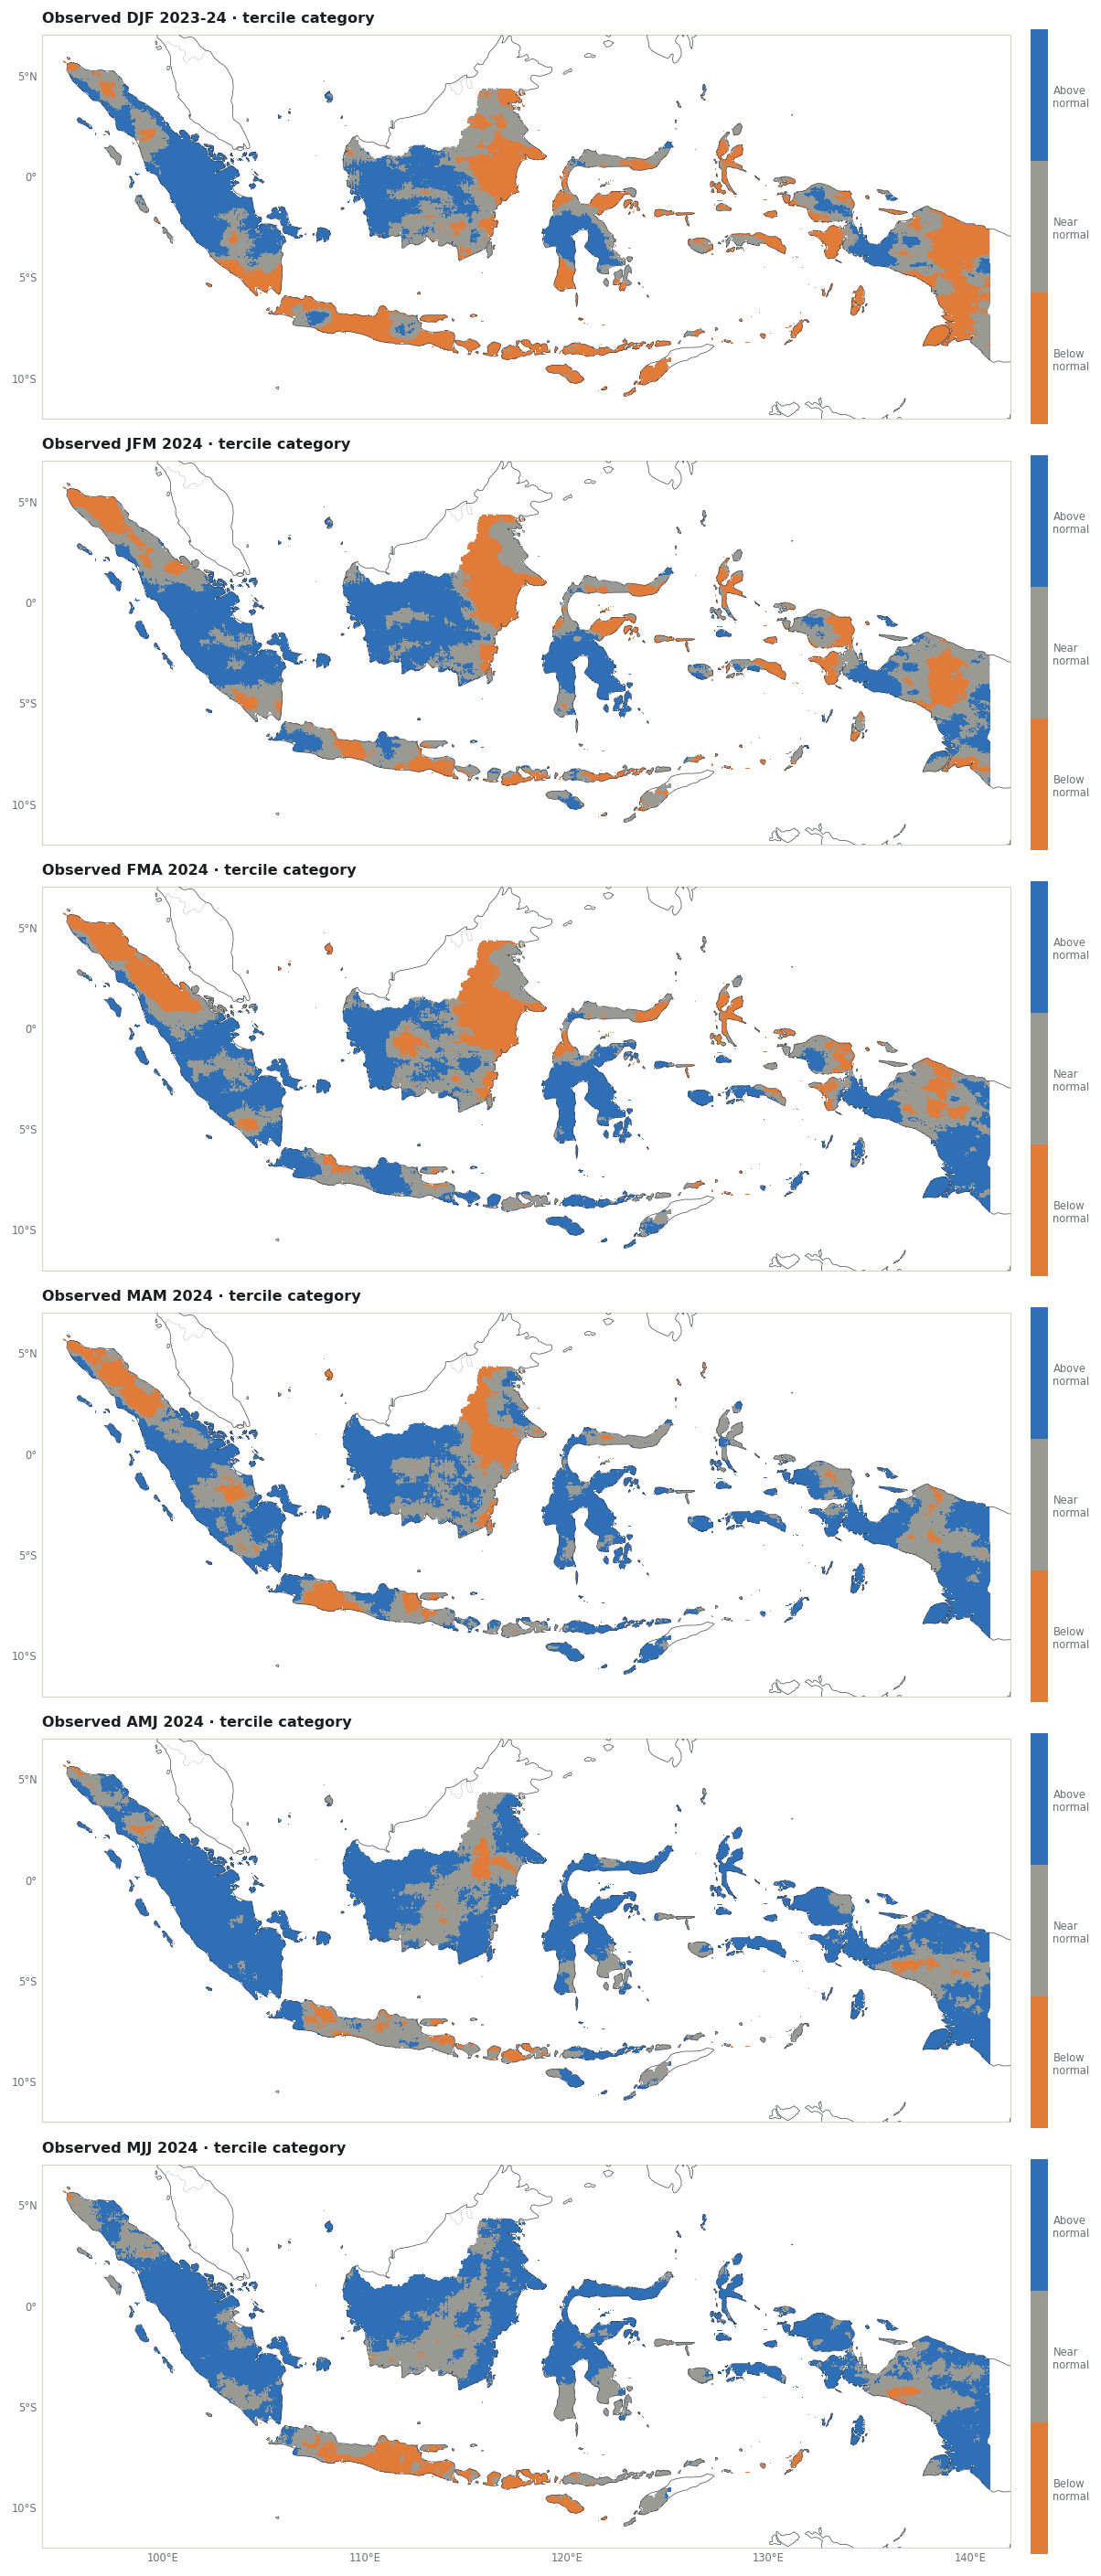

In [15]:
def category_bar(fig, image, ax):
    # a colour bar with the three category names, so every map in a column has the same width
    bar = figures.colorbar(fig, image, ax, "", ticks=[0, 1, 2])
    bar.ax.set_yticklabels(["Below\nnormal", "Near\nnormal", "Above\nnormal"])
    return bar


fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    category_bar(fig, figures.category_map(ax, observed[lead]["category"]), ax)
    ax.set_title(f"Observed {label[lead]} · tercile category")
fig.savefig(assets / "observed-by-lead.png")
plt.show()

Now the forecasts. Each lead gives a probability for each category at each cell.
Three ways to score them against what happened, each area-weighted over the pixels:

- **Hit rate**: share of area where the most likely category was the one observed.
  Always forecasting one category would hit the area where that category happened;
  the **reference hit rate** above is the best such constant guess, chosen with
  hindsight.
- **RPSS**: ranked probability skill score of this one target's probabilities
  against climatological odds (33/34/33%). Above 0 means closer to what happened
  than climatology; it is one outcome, not a skill estimate.
- **RMSE**: error of the deterministic forecast in mm.

The table also gives the share of the area where each category was the most likely
one, to see whether a hit rate comes from placing categories well or from favouring
the category that happened almost everywhere.

In [16]:
def rps(probability, category):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(category <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


clim = xr.DataArray([33.0, 34.0, 33.0], dims="C")
forecast_rows, most_likely, deterministic = [], {}, {}
for lead in leads:
    o = observed[lead]
    valid = o["category"].notnull()
    for MOS in ["CCA", "PCR"]:
        f = results["issue", lead, MOS]["fcsts"]
        p = on_grid(f.probabilistic.isel(T=0))
        clim_p = clim.assign_coords(C=p["C"]).broadcast_like(p)
        m = p.fillna(-1).argmax("C").where(p.notnull().all("C") & valid)
        most_likely[lead, MOS] = (m, p.max("C"))
        w = weights.where(m.notnull(), 0)                       # pixels with both a forecast and an observation
        det = on_grid(f.deterministic.isel(T=0)).where(cells)
        deterministic[lead, MOS] = det
        forecast_rows.append({"lead": lead, "target": label[lead], "method": MOS,
                              "hit rate (%)": float(w.where(m == o["category"], 0).sum() / w.sum() * 100),
                              "RPSS": float(1 - rps(p, o["category"]).weighted(w).mean() / rps(clim_p, o["category"]).weighted(w).mean()),
                              "RMSE (mm)": float(np.sqrt(((det - o["total"]) ** 2).weighted(w).mean())),
                              "mean forecast (mm)": float(det.weighted(w).mean()),
                              "observed mean (mm)": float(o["total"].weighted(w).mean()),
                              **{f"area forecast {name} (%)": float(w.where(m == k, 0).sum() / w.sum() * 100)
                                 for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(forecast_rows).set_index(["lead", "method"]).sort_index()
forecast_2023.round(2)

target  hit rate (%)  RPSS  RMSE (mm)  mean forecast (mm)  \
lead method                                                                   
1    CCA     DJF 2023-24         46.28  0.12     163.47              775.48   
     PCR     DJF 2023-24         47.92  0.12     163.77              753.34   
2    CCA        JFM 2024         35.70 -0.01     170.42              791.71   
     PCR        JFM 2024         40.17  0.03     164.92              800.97   
3    CCA        FMA 2024         34.76 -0.00     176.14              771.34   
     PCR        FMA 2024         37.37  0.04     171.80              781.14   
4    CCA        MAM 2024         24.66 -0.16     225.32              759.88   
     PCR        MAM 2024         28.32 -0.15     228.76              770.76   
5    CCA        AMJ 2024         21.15 -0.15     247.19              697.96   
     PCR        AMJ 2024         38.75 -0.05     240.07              727.53   
6    CCA        MJJ 2024         56.91  0.16     157.58              717.06   
     PCR        MJJ 2024         55.96  0.15     180.69              722.52   

             observed mean (mm)  area forecast below (%)  \
lead method                                                
1    CCA                 842.12                    70.58   
     PCR                 842.12                    78.31   
2    CCA                 871.21                    65.59   
     PCR                 871.21                    56.38   
3    CCA                 875.05                    72.36   
     PCR                 875.05                    67.00   
4    CCA                 920.00                    79.32   
     PCR                 920.00                    69.95   
5    CCA                 881.24                    66.20   
     PCR                 881.24                    41.61   
6    CCA                 734.31                     6.65   
     PCR                 734.31                     6.97   

             area forecast near (%)  area forecast above (%)  
lead method                                                   
1    CCA                       5.11                    24.31  
     PCR                       1.87                    19.82  
2    CCA                       1.87                    32.54  
     PCR                       4.19                    39.44  
3    CCA                       3.41                    24.23  
     PCR                       3.03                    29.96  
4    CCA                       3.19                    17.49  
     PCR                       2.26                    27.79  
5    CCA                      11.62                    22.18  
     PCR                       4.17                    54.22  
6    CCA                       4.45                    88.90  
     PCR                       3.13                    89.91

The CCA forecasts' most likely category at each lead, in one column. Compare each
map with the same lead in the observed column above.

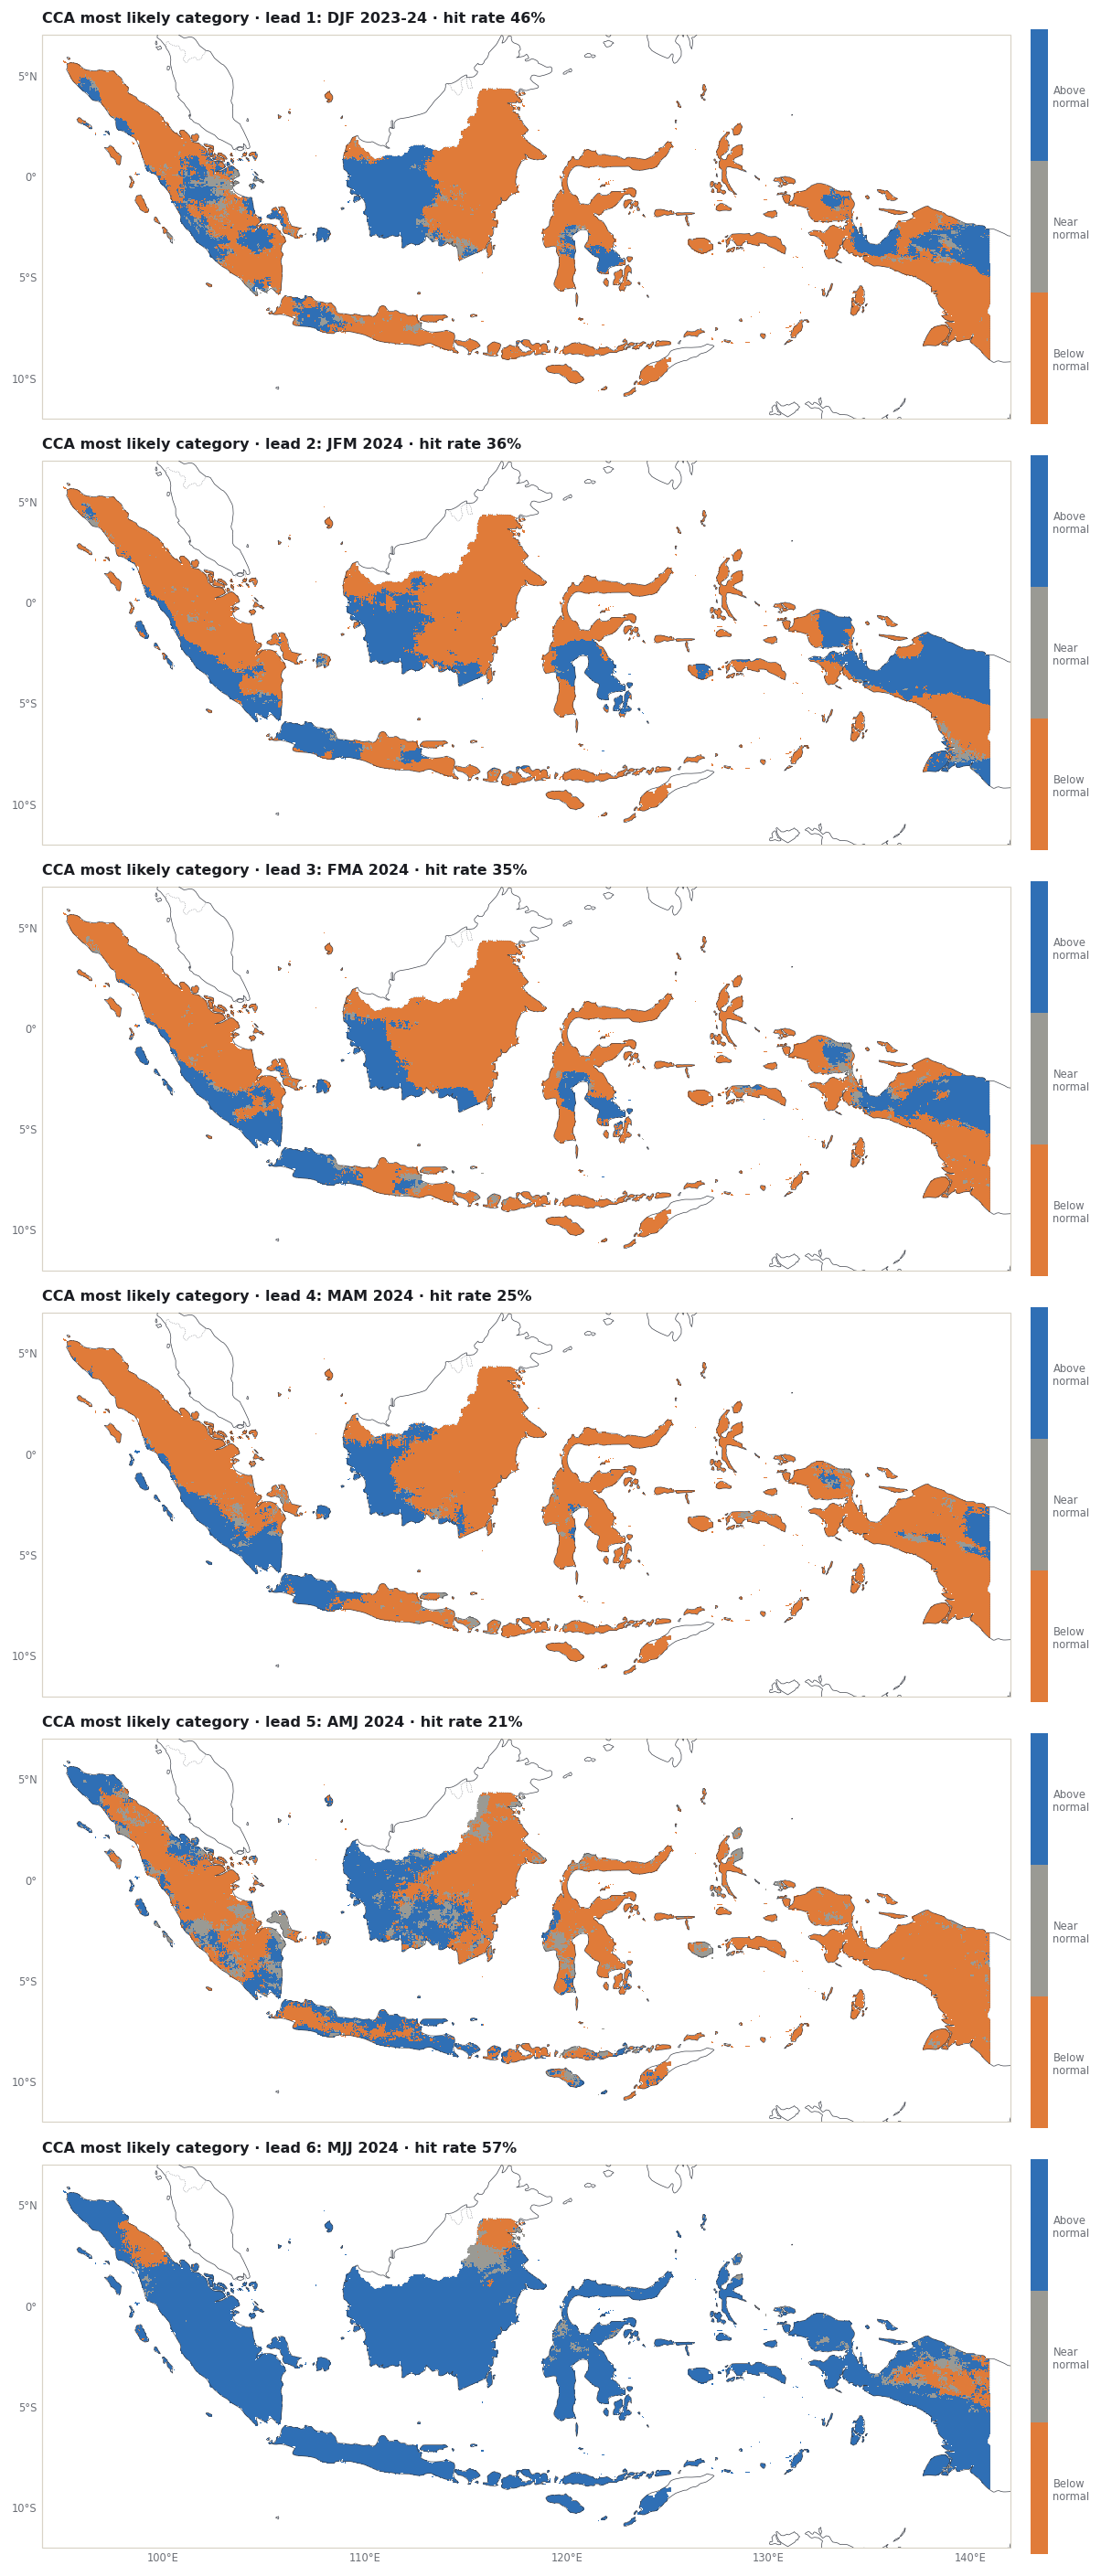

In [17]:
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    category_bar(fig, figures.category_map(ax, most_likely[lead, "CCA"][0]), ax)
    hit = forecast_2023.loc[(lead, "CCA"), "hit rate (%)"]
    ax.set_title(f"CCA most likely category · lead {lead}: {label[lead]} · hit rate {hit:.0f}%")
fig.savefig(assets / "cca-category-by-lead.png")
plt.show()

## 9. Save the results

The story page quotes these tables and draws its interactive views from the JSON
file written at the end.

In [18]:
data_dir = repo / "docs/data/seasonal-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
forecast_2023.round(4).to_csv(data_dir / "issued-2023-11-forecasts.csv")
targets_2023.round(4).to_csv(data_dir / "issued-2023-11-observed.csv")
same_target.round(4).to_csv(data_dir / "same-target-skill.csv")
if "comparison" in globals():
    comparison.round(4).to_csv(data_dir / "seasonal-vs-monthly.csv")
summary = {"issued": issue.date().isoformat(), "leads_months": leads,
           "targets": {lead: {"pycpt_target": targets[lead], "label": label[lead],
                               "first_day": str(inputs["issue", lead]["F"][0]["Ti"].values[0])[:10],
                               "last_day": str(inputs["issue", lead]["F"][0]["Tf"].values[0])[:10]} for lead in leads},
           "same_target": {"target": fixed_target, "starts": {lead: s.date().isoformat() for lead, s in fixed_starts.items()}},
           "training_target_years": [training_years[0], training_years[-1]], "pixels": int(cells.sum()), "grid": "native 0.05 degree",
           "settings": {k: str(v) for k, v in cpt_args.items()},
           "fit_seconds": {f"{k[0]}-{k[1]}-{k[2]}": round(r["seconds"], 1) for k, r in results.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    maps[f"observed_lead{lead}"] = observed[lead]["total"].reset_coords(drop=True)
    maps[f"observed_category_lead{lead}"] = observed[lead]["category"].reset_coords(drop=True)
    for MOS in ["CCA", "PCR"]:
        maps[f"{MOS.lower()}_pearson_lead{lead}"] = on_grid(results["issue", lead, MOS]["skill"].pearson).reset_coords(drop=True)
        maps[f"{MOS.lower()}_forecast_lead{lead}"] = deterministic[lead, MOS].reset_coords(drop=True)
        maps[f"{MOS.lower()}_most_likely_lead{lead}"] = most_likely[lead, MOS][0].reset_coords(drop=True)
save_netcdf(maps, data_dir / "seasonal-leads-2023-maps.nc", overwrite=True,
            metadata={"note": "CFSv2 started 1 November 2023, leads 1-6 months (DJF 2023-24 to MJJ 2024), CCA and PCR; categories 0 below, 1 near, 2 above normal"})
for f in sorted(data_dir.iterdir()) + sorted(assets.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/seasonal-leads-2023/issued-2023-11-forecasts.csv  (1 kB)
docs/data/seasonal-leads-2023/issued-2023-11-observed.csv  (1 kB)
docs/data/seasonal-leads-2023/same-target-skill.csv  (0 kB)
docs/data/seasonal-leads-2023/seasonal-leads-2023-maps.nc  (13441 kB)
docs/data/seasonal-leads-2023/seasonal-vs-monthly.csv  (1 kB)
docs/data/seasonal-leads-2023/skill-by-lead.csv  (1 kB)
docs/data/seasonal-leads-2023/summary.json  (2 kB)
docs/assets/seasonal-leads-2023/cca-category-by-lead.png  (1224 kB)
docs/assets/seasonal-leads-2023/cca-pearson-by-lead.png  (1985 kB)
docs/assets/seasonal-leads-2023/interactive-data.json  (1529 kB)
docs/assets/seasonal-leads-2023/observed-by-lead.png  (1209 kB)
docs/assets/seasonal-leads-2023/same-target-vs-issue.png  (104 kB)
docs/assets/seasonal-leads-2023/seasonal-vs-monthly.png  (88 kB)
docs/assets/seasonal-leads-2023/skill-by-lead.png  (111 kB)


The story page's interactive maps and charts read a small manifest and, at 0.05°, one
gzip-compressed binary file per map, loaded only when a view needs it: integers at a
stated scale, stored only at the Indonesian pixels in the order of a shared pixel list.

In [19]:
import gzip


def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


field_dir = assets / "fields"
field_dir.mkdir(exist_ok=True)
for old in list(field_dir.glob("*")) + [assets / "interactive-data.json"]:
    old.unlink(missing_ok=True)
grid_mask = cells.transpose("Y", "X")
flat = np.flatnonzero(grid_mask.values.ravel())                    # row 0 = northernmost pixel row
n = len(flat)


def at_pixels(a):
    return np.asarray(on_grid(a).transpose("Y", "X").values, dtype="float64").ravel()[flat]


def encode(values, kind, scale):
    v = np.round(values * scale)
    if kind == "i16":
        return np.where(np.isfinite(v), np.clip(v, -32767, 32767), -32768).astype("<i2").tobytes()
    if kind == "u16":
        return np.where(np.isfinite(v), np.clip(v, 0, 65534), 65535).astype("<u2").tobytes()
    return np.where(np.isfinite(v), np.clip(v, 0, 254), 255).astype("u1").tobytes()


def write(name, parts):
    (field_dir / f"{name}.bin.gz").write_bytes(gzip.compress(b"".join(encode(*q) for q in parts), 9, mtime=0))


(assets / "pixels.bin").write_bytes(flat.astype("<i4").tobytes())
lead_key = {lead: f"lead{lead}" for lead in leads}
target_info, issue_targets = [], []
for lead in leads:
    F0 = inputs["issue", lead]["F"][0]
    first, last = pd.Timestamp(F0["Ti"].values[0]), pd.Timestamp(F0["Tf"].values[0])
    days = (last - first).days + 1
    target_info.append({"lead": lead, "label": label[lead], "pycpt": targets[lead], "start": f"{first:%Y-%m-%d}",
                        "end": f"{last + pd.Timedelta(days=1):%Y-%m-%d}"})
    issue_targets.append({"lead": lead_key[lead], "start": f"{first:%Y-%m-%d}", "days": int(days)})
    write(f"obs-{days}-{first:%Y-%m-%d}", [(at_pixels(observed[lead]["total"]), "u16", 10), (at_pixels(observed[lead]["mean"]), "u16", 10),
                                              (at_pixels(observed[lead]["category"]), "u8", 1)])
    for m in ["CCA", "PCR"]:
        write(f"skill-{m}-pearson-{lead_key[lead]}", [(at_pixels(results["issue", lead, m]["skill"].pearson), "i16", 1000)])
        write(f"skill-{m}-twoafc-{lead_key[lead]}", [(at_pixels(results["issue", lead, m]["skill"].two_alternative_forced_choice), "i16", 10)])
        write(f"fc-{lead_key[lead]}-{m}-{first:%Y-%m-%d}", [(at_pixels(deterministic[lead, m]), "u16", 10),
                                                                (at_pixels(most_likely[lead, m][0]), "u8", 1),
                                                                (at_pixels(most_likely[lead, m][1].where(cells)), "u8", 1)])
    write(f"skill-raw-pearson-{lead_key[lead]}", [(at_pixels(raw_pearson[lead]), "i16", 1000)])

values = np.concatenate([observed[lead]["total"].values.ravel() for lead in leads] + [deterministic[k].values.ravel() for k in deterministic])
top = float(np.ceil(np.nanpercentile(values, 99) / 100) * 100)
manifest = {
    "grid": {"west": round(float(grid_mask.X.min()) - .025, 3), "north": round(float(grid_mask.Y.max()) + .025, 3), "step": 0.05,
             "nx": int(grid_mask.sizes["X"]), "ny": int(grid_mask.sizes["Y"]), "pixels": n},
    "kind": "season", "issue": {"date": issue.date().isoformat(), "label": "1 Nov 2023"},
    "issues": [{"issued": issue.date().isoformat(), "label": "1 Nov 2023", "targets": issue_targets}],
    "leads": leads, "leadKeys": [lead_key[lead] for lead in leads], "methods": ["CCA", "PCR"], "rawName": "raw CFSv2", "unit": "mm",
    "training": "1991-2020", "sample": "the 30 training years, 1991-2020", "cellText": f"Indonesia's {n:,} pixels at 0.05°",
    "leadNames": [f"Lead {lead} · {label[lead]}" for lead in leads],
    "targets": target_info,
    "layout": {"skill": [["value", "i16"]], "obs": [["total", "u16", 10], ["mean", "u16", 10], ["category", "u8", 1]],
               "fc": [["total", "u16", 10], ["category", "u8", 1], ["probability", "u8", 1]]},
    "scales": {"pearson": 1000, "twoafc": 10},
    "rainMax": {str(t["days"]): top for t in issue_targets}, "rainLegend": "mm in the season",
    "mapsHint": "Lead 1 at the top. Each map is a different target; hover a pixel for the forecast, the observation and that target's 1991-2020 mean.",
    "skillTable": records(skill_by_lead.reset_index().round(4)),
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "references": records(targets_2023.reset_index().round(3)),
    "sameTarget": {"target": "October-December 2023", "rows": records(same_target.reset_index().round(4))},
}
if "comparison" in globals():
    manifest["comparison"] = records(comparison.reset_index().round(4))
(assets / "manifest.json").write_text(json.dumps(manifest, separators=(",", ":"), allow_nan=False) + "\n")
sizes = sorted(q.stat().st_size for q in field_dir.iterdir())
print(f"{n:,} pixels; {len(sizes)} field files, {sum(sizes) / 1e6:.1f} MB in total (largest {sizes[-1] / 1e3:.0f} kB); "
      f"colour scale up to {top:.0f} mm")

61,190 pixels; 48 field files, 5.5 MB in total (largest 226 kB); colour scale up to 1600 mm


## References {.unnumbered .reference-section}

1. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
2. IRI. *PyCPT 2.10.4 source: `cptdl`* (data catalog, `leads_from_target`, `evaluate_url`, `download`, `simple_download`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/tree/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptdl>
3. IRI. *CPT 17.8.3 source code archive*. Columbia University Academic Commons. <https://doi.org/10.7916/fdp6-v391>
4. CPT+. *Forecast Probabilities* (CPT help). <https://cptplus.org/Help/Tools_Forecast_Probs.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
5. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
6. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
7. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
8. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
9. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
10. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
11. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
12. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
13. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
14. Barnston, A. G., and van den Dool, H. M. (1993). A degeneracy in cross-validated skill in regression-based forecasts. *Journal of Climate*, 6(5), 963-977. <https://doi.org/10.1175/1520-0442(1993)006%3C0963:ADICVS%3E2.0.CO;2>
15. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>